In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\NLP DataSets\cyberbullying-dataset.xlsx")
df

,TEXT,TOXICITY
0,hey what is it talk what is it an exclusive gr...,0
1,bye dont look come or think of comming back to...,1
2,i m sorry i m sorry i screwed around with some...,3
3,why can t you believe how fat artie is did you...,1
4,sorry puck but no one ever said dick was numbe...,1
...,...,...
33749,epic is that lils wanyes bro because they are ...,0
33750,i dont give a shit who you are but if it would...,3
33751,is that ron jeremy spotting him dee snider you...,2
33752,justin looked like he was enjoying some of nic...,3


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 33754 entries, 0 to 33753
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   TEXT      33736 non-null  str  
 1   TOXICITY  33754 non-null  int64
dtypes: int64(1), str(1)
memory usage: 527.5 KB


In [4]:
df.isnull().sum()

TEXT        18
TOXICITY     0
dtype: int64

In [5]:
df.nunique()

TEXT        33409
TOXICITY        6
dtype: int64

In [6]:
df["TEXT"] = df["TEXT"].fillna(df["TEXT"].mode()[0])
df.isnull().sum()

TEXT        0
TOXICITY    0
dtype: int64

In [7]:
df.describe()

,TOXICITY
count,33754.000000
mean,1.766813
std,1.596384
min,0.000000
25%,0.000000
50%,1.000000
75%,3.000000
max,5.000000


In [8]:
df.to_csv("Cyber_Bullying_Final.csv", index=False)

In [9]:
df = df.rename(columns={"TEXT":"text","TOXICITY":"class"})
df.head()

,text,class
0,hey what is it talk what is it an exclusive gr...,0
1,bye dont look come or think of comming back to...,1
2,i m sorry i m sorry i screwed around with some...,3
3,why can t you believe how fat artie is did you...,1
4,sorry puck but no one ever said dick was numbe...,1


In [10]:
import re 
import string

def wordopt(text):
    text = text.lower()
    text = re.sub('\[.*?\]','',text)
    text = re.sub("\\W"," ",text)
    text = re.sub('https?://\S+|www\.\S+','',text)
    text = re.sub('<.*?>+','',text)
    text = re.sub('[%s]'%re.escape(string.punctuation),'',text)
    text = re.sub('\n','',text)
    text = re.sub('\w*\d\w*','',text)
    return text

<>:6: SyntaxWarning: "\[" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\["? A raw string is also an option.
<>:8: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
<>:12: SyntaxWarning: "\w" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\w"? A raw string is also an option.
<>:6: SyntaxWarning: "\[" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\["? A raw string is also an option.
<>:8: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
<>:12: SyntaxWarning: "\w" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\w"? A raw string is also an option.
C:\Users\vimal_z0\AppData\Local\Temp\ipykernel_37692\2333894466.py:6: SyntaxWarn

In [11]:
df["text"] = df["text"].apply(wordopt)

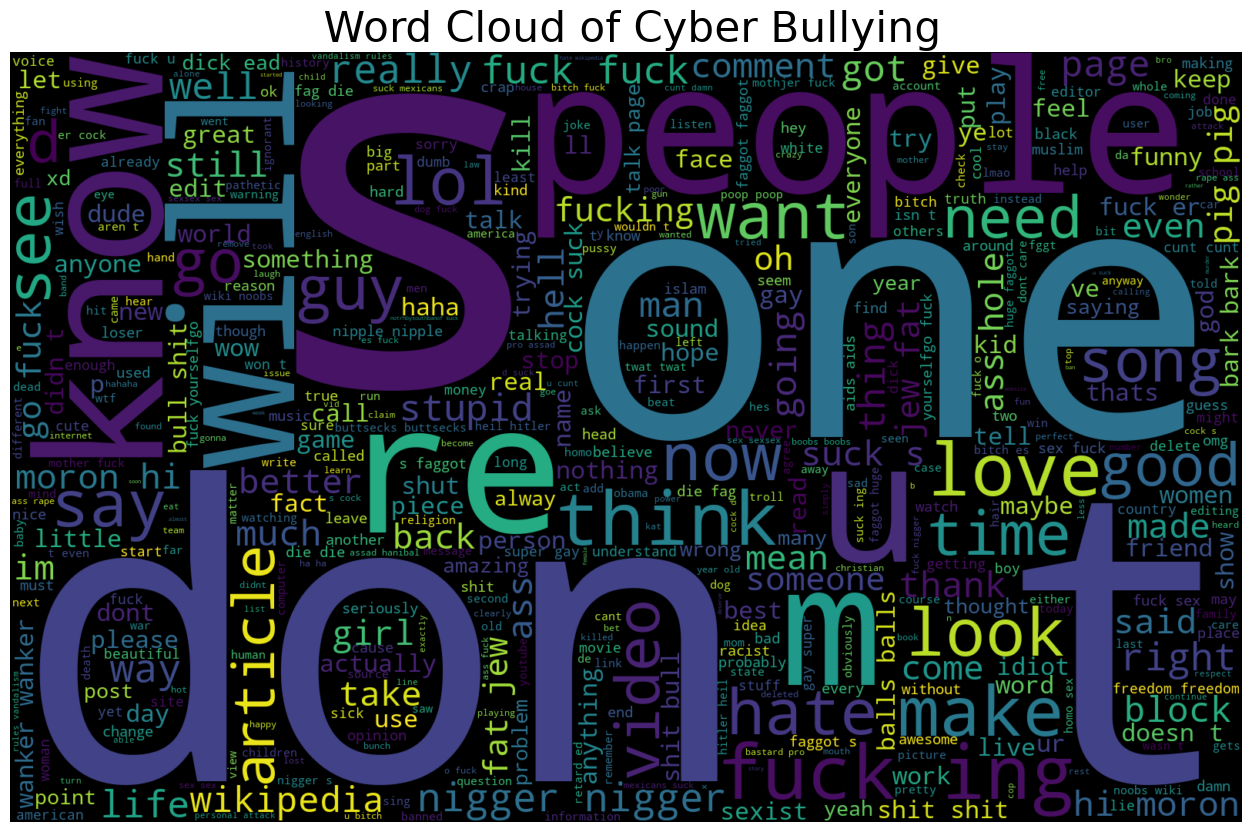

In [23]:
from wordcloud import WordCloud

txt =" ".join([i for i in df["text"]])
wordcloud = WordCloud(max_words=500, width = 1600, height =1000).generate(txt)
plt.figure(figsize=(20,10))
plt.imshow(wordcloud, interpolation ='bilinear')
plt.title(" Word Cloud of Cyber Bullying", fontsize=30)
plt.axis('off')
plt.show()

In [13]:
x = df["text"]
y = df["class"]

In [20]:
print(x)

0        hey what is it talk what is it an exclusive gr...
1        bye dont look come or think of comming back to...
2        i m sorry i m sorry i screwed around with some...
3        why can t you believe how fat artie is did you...
4        sorry puck but no one ever said dick was numbe...
                               ...                        
33749    epic is that lils wanyes bro because they are ...
33750    i dont give a shit who you are but if it would...
33751    is that ron jeremy spotting him dee snider you...
33752    justin looked like he was enjoying some of nic...
33753    she pretty i love this song i miss the old kel...
Name: text, Length: 33754, dtype: str


In [14]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.25, random_state=42)

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer()
xv_train = vectorizer.fit_transform(x_train)
xv_test = vectorizer.transform(x_test)

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
lr = LogisticRegression(max_iter=300)
lr.fit(xv_train, y_train)
lr_acc = lr.score(xv_test, y_test)
print("Accuracy of Logistic:", round(lr_acc*100,2))

Accuracy of Logistic: 52.26


In [19]:
from sklearn.tree import DecisionTreeClassifier
dtc = DecisionTreeClassifier(random_state=42)
dtc.fit(xv_train, y_train)
dtc_acc= dtc.score(xv_test, y_test)
print("Accuracy of Decision Tree:", round(dtc_acc*100,2))

Accuracy of Decision Tree: 41.62


In [26]:
from sklearn.ensemble import AdaBoostClassifier
abc = AdaBoostClassifier(random_state=42)
abc.fit(xv_train, y_train)
abc_acc = abc.score(xv_test, y_test)
print("Accuracy of AdaBoost:", round(abc_acc*100,2))

Accuracy of AdaBoost: 37.99


In [27]:
pd.set_option("display.max_colwidth", None)

In [30]:
x.head()

0                                                                                                                                                                                                                                                 hey what is it talk what is it an exclusive group of some wp talibans who are good at destroying self appointed purist who gang up any one who asks them questions abt their anti social and destructive non contribution at wp ask sityush to clean up his behavior than issue me nonsensical warnings
1                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

In [29]:
y.head()

0    0
1    1
2    3
3    1
4    1
Name: class, dtype: int64

In [31]:
ex =["i m sorry i m sorry i screwed around with someones talk page it was very bad to do i know how having the templates on their talk page helps you assert your dominance over them i know i should bow down to the almighty administrators but then again i m going to go play outside with your mom"]
ex_vectorized = vectorizer.transform(ex)
result = lr.predict(ex_vectorized)
print(result)

[1]
